# SIT307 – Machine Learning
## 11.1HD – Machine Learning Mini Research

### Reproduction and Improvement of a Stacking-Based Ensemble for Heart Disease Prediction

**Selected Research Paper:**  
*An Efficient Stacking-Based Ensemble Technique for Early Heart Attack Prediction*

**Authors:** Monu Bhagat, Aayush Sharma and Piyanshi Agarwal

---

### Notebook Purpose

This notebook is used to reproduce the machine learning method from the selected research paper and check whether I can get similar results using the same dataset and methods explained by the authors.

The paper focuses on heart disease prediction using six different machine learning classifiers and a stacking ensemble model. First, I will reproduce the original method and compare my results with the results given in the paper.

After that, I will look at one limitation of the original method and try to create an improved machine learning approach.

All experiments in this notebook will be kept in a clear and reproducible way so the results used in my final report can be generated again from the notebook.

## 1. Introduction

Heart disease is one of the major health problems in many countries, and early prediction can help with better treatment and prevention.

Machine learning can be used to analyse patient health information and identify patterns that may be linked with heart disease. Different machine learning models can give different results, so the selected paper tests several classifiers and also combines them using a stacking ensemble method.

In this task, I will reproduce the main experiment from the paper using the same heart disease dataset and similar machine learning methods. I will then compare my results with the results reported by the authors and discuss any differences I find.`

## 1.1 Research Problem

The main problem in this study is how to predict heart disease accurately using patient clinical information.

A single machine learning model may not always give the best result because different models learn patterns in different ways. Because of this, the selected paper compares several classifiers and then uses a stacking ensemble method to combine their predictions.

The idea is to check whether combining multiple models can give better prediction performance than using only one model.

## 1.2 Aim and Objectives

The main aim of this experiment is to reproduce the machine learning approach used in the selected paper and compare my results with the published results.

For this task, I will:

- use the heart disease dataset described in the paper
- prepare the data before training the models
- train the six individual machine learning classifiers used by the authors
- evaluate the models using Accuracy, Precision, Recall, F1-score and AUC
- build the stacking ensemble model
- compare my reproduced results with the results from the paper
- discuss any differences between the results
- identify one limitation in the original method and develop an improved approach for Part 2

## 1.3 Selected Research Paper

For this task, I selected the paper **“An efficient stacking-based ensemble technique for early heart attack prediction”** by Monu Bhagat, Aayush Sharma and Piyanshi Agarwal.

The paper uses six different machine learning classifiers:

- Logistic Regression
- Decision Tree
- Random Forest
- XGBoost
- Naive Bayes
- K-Nearest Neighbours

After testing these models separately, the authors use a stacking ensemble technique to combine the predictions from multiple models.

The paper reports that the stacking approach performs better than the individual classifiers, which is the main result I will try to reproduce in this notebook.

## 1.4 Notebook Workflow

I will complete this notebook in two main parts.

### Part 1 – Reproducing the Paper

First, I will reproduce the main machine learning process from the selected paper. This includes:

1. loading and checking the dataset
2. preparing the data
3. training the six individual classifiers
4. evaluating each model
5. building the stacking ensemble model
6. comparing my results with the published results
7. discussing any differences I find

### Part 2 – Improving the Original Method

After completing the reproduction, I will identify one limitation in the original approach and develop an improved machine learning method.

I will then evaluate the improved method and compare it with both my reproduced baseline and the results reported in the paper.

# 2. Reproduction Study

## 2.1 Dataset Used

For this reproduction, I used the Heart Disease Dataset linked in the selected research paper.

The dataset contains **1,025 records and 14 columns**. Out of these, 13 columns are used as input features and the `target` column is used as the output.

The target values are:

- `0` = No heart disease
- `1` = Heart disease

The dataset includes patient information such as age, sex, chest pain type, resting blood pressure, cholesterol level, fasting blood sugar, maximum heart rate and exercise-induced angina.

## 2.2 Importing Required Libraries

Before starting the experiment, I imported the Python libraries needed for loading the dataset, preparing the data, training the machine learning models and evaluating the results.

The main libraries used in this notebook are:

- `pandas` and `numpy` for working with the dataset
- `matplotlib` for graphs and visualisations
- `scikit-learn` for preprocessing, machine learning models and evaluation
- `xgboost` for the XGBoost classifier used in the selected paper

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from xgboost import XGBClassifier
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, StackingClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    RocCurveDisplay
)

from xgboost import XGBClassifier

print("Libraries imported successfully.")

Libraries imported successfully.


## 2.3 Loading the Dataset

The heart disease dataset used in the selected paper was loaded into the notebook using pandas.

After loading the dataset, I checked the number of rows and columns and displayed the first few records to make sure the file was loaded correctly.

In [2]:
df = pd.read_csv("heart.csv")

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (1025, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,52,1,0,125,212,0,1,168,0,1.0,2,2,3,0
1,53,1,0,140,203,1,0,155,1,3.1,0,0,3,0
2,70,1,0,145,174,0,1,125,1,2.6,0,0,3,0
3,61,1,0,148,203,0,1,161,0,0.0,2,1,3,0
4,62,0,0,138,294,1,1,106,0,1.9,1,3,2,0


The dataset was loaded successfully.

It contains **1,025 rows and 14 columns**, which matches the dataset size described in the selected paper. The displayed records also show the expected clinical features such as age, chest pain type, cholesterol, maximum heart rate and the `target` column.

## 2.4 Inspecting the Dataset

Before preprocessing the data, I checked the column names, data types, missing values and duplicate records.

This helps me understand the structure of the dataset and identify any data quality issues that may affect the machine learning models.

In [3]:
print("Column names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())

Column names:
['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target']

Data types:
age           int64
sex           int64
cp            int64
trestbps      int64
chol          int64
fbs           int64
restecg       int64
thalach       int64
exang         int64
oldpeak     float64
slope         int64
ca            int64
thal          int64
target        int64
dtype: object

Missing values:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
target      0
dtype: int64

Duplicate rows:
723


The dataset inspection shows that all expected columns are available and there are no missing values.

Most columns are stored as integer values, while `oldpeak` is stored as a decimal value.

The dataset also contains **723 duplicate rows**. Since the selected paper reports using the full 1,025-record dataset, I will keep these records for the reproduction stage so that my setup stays as close as possible to the published experiment.

I will consider the effect of these duplicate records later when discussing limitations and possible improvements.

## 2.5 Checking the Target Distribution

Next, I checked how many records belong to each target class.

This is important because a highly imbalanced target could affect the accuracy and other evaluation results.

In [4]:
target_counts = df["target"].value_counts().sort_index()
target_percent = df["target"].value_counts(normalize=True).sort_index() * 100

print("Target counts:")
print(target_counts)

print("\nTarget percentages:")
print(target_percent.round(2))

Target counts:
target
0    499
1    526
Name: count, dtype: int64

Target percentages:
target
0    48.68
1    51.32
Name: proportion, dtype: float64


The target distribution is almost balanced.

There are **499 records without heart disease (48.68%)** and **526 records with heart disease (51.32%)**.

Since both classes are represented in similar amounts, the dataset does not have a major class imbalance problem. This means I do not need to apply balancing techniques at this stage.

## 2.6 Descriptive Statistics

Next, I checked the basic statistical summary of the dataset.

This gives a quick overview of the minimum, maximum, mean and spread of the numerical features before starting the preprocessing and model training steps.

In [5]:
display(df.describe().T)

,count,mean,std,min,25%,50%,75%,max
age,1025.0,54.434146,9.072290,29.0,48.0,56.0,61.0,77.0
sex,1025.0,0.695610,0.460373,0.0,0.0,1.0,1.0,1.0
cp,1025.0,0.942439,1.029641,0.0,0.0,1.0,2.0,3.0
trestbps,1025.0,131.611707,17.516718,94.0,120.0,130.0,140.0,200.0
chol,1025.0,246.000000,51.592510,126.0,211.0,240.0,275.0,564.0
fbs,1025.0,0.149268,0.356527,0.0,0.0,0.0,0.0,1.0
restecg,1025.0,0.529756,0.527878,0.0,0.0,1.0,1.0,2.0
thalach,1025.0,149.114146,23.005724,71.0,132.0,152.0,166.0,202.0
exang,1025.0,0.336585,0.472772,0.0,0.0,0.0,1.0,1.0
oldpeak,1025.0,1.071512,1.175053,0.0,0.0,0.8,1.8,6.2


The descriptive statistics show that the features have quite different value ranges.

For example, `chol` and `trestbps` have much larger numerical values compared with features such as `sex`, `fbs` and `exang`, which only use small categorical values.

This is important because some machine learning models, especially KNN and Logistic Regression, can be affected by differences in feature scale. Because of this, scaling will be included during preprocessing.

## 2.7 Checking Feature Correlation

Next, I checked the correlation between the numerical features and the target.

This helps me get an initial idea of which features have stronger relationships with heart disease before training the machine learning models.

In [6]:
correlation = df.corr(numeric_only=True)

target_correlation = correlation["target"].sort_values(ascending=False)

display(target_correlation)

target      1.000000
cp          0.434854
thalach     0.422895
slope       0.345512
restecg     0.134468
fbs        -0.041164
chol       -0.099966
trestbps   -0.138772
age        -0.229324
sex        -0.279501
thal       -0.337838
ca         -0.382085
exang      -0.438029
oldpeak    -0.438441
Name: target, dtype: float64

The correlation results show that some features have a stronger relationship with heart disease than others.

`cp` and `thalach` have the strongest positive relationships with the target. On the other hand, `oldpeak` and `exang` show stronger negative relationships.

Features such as `fbs`, `chol` and `restecg` have much weaker correlations with the target.

These values only show simple relationships between individual features and the target, so I will not remove any features based only on this result.

### Correlation Heatmap

To view the relationships between all features more clearly, I also created a correlation heatmap.

This makes it easier to see which features are positively or negatively related to each other and to the target.

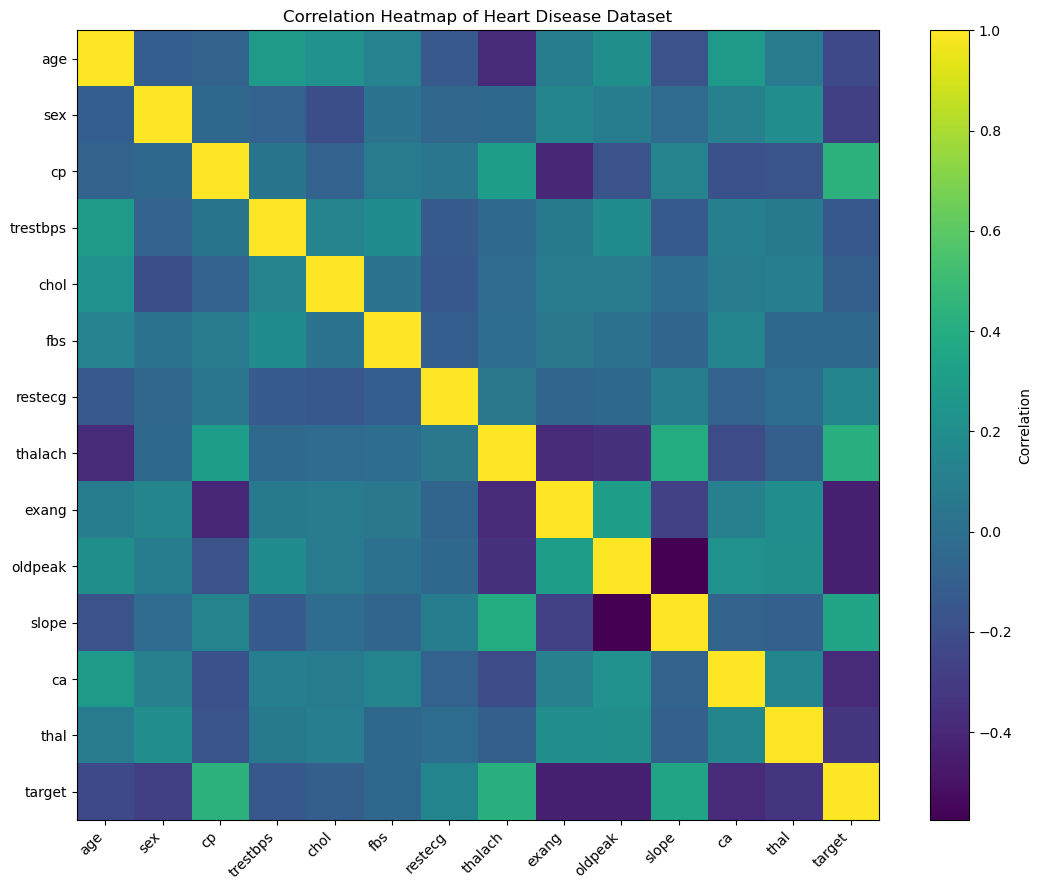

In [7]:
fig, ax = plt.subplots(figsize=(11, 9))

heatmap = ax.imshow(correlation, aspect="auto")

ax.set_xticks(range(len(correlation.columns)))
ax.set_yticks(range(len(correlation.columns)))

ax.set_xticklabels(correlation.columns, rotation=45, ha="right")
ax.set_yticklabels(correlation.columns)

fig.colorbar(heatmap, ax=ax, label="Correlation")

ax.set_title("Correlation Heatmap of Heart Disease Dataset")

plt.tight_layout()
plt.show()

The heatmap shows that the features do not all have the same relationship with the target.

Some features such as `cp` and `thalach` show a more positive relationship with heart disease, while `exang`, `oldpeak`, `ca` and `thal` show more negative relationships.

I will still keep all features for the reproduction because the selected paper uses the full set of 14 attributes in the experiment.

## 2.8 Data Preprocessing

The selected paper mentions preprocessing steps such as handling missing values, scaling and preparing categorical values before training the models.

In my dataset, there are no missing values, so no missing-value treatment is required.

For this reproduction, I will separate the input features from the target first. I will then split the data into training and testing sets before applying scaling so that information from the test set is not used during training.

In [8]:
X = df.drop("target", axis=1)
y = df["target"]

print("Input shape:", X.shape)
print("Target shape:", y.shape)

Input shape: (1025, 13)
Target shape: (1025,)


The dataset is now separated into the input features and target variable.

The input data contains **13 features**, while the target contains **1,025 values** showing whether heart disease is present or not.

This matches the structure described in the selected paper.

### Preprocessing Assumptions

The selected paper states that preprocessing includes handling missing values, scaling numerical values and encoding categorical variables.

In the dataset used for this reproduction, no missing values were found, so no imputation was required.

The categorical variables were already stored as numerical codes, so no additional encoding step was applied.

The paper does not clearly specify the exact scaling method used. For this reproduction, I used `StandardScaler` for models that are sensitive to feature scale, such as Logistic Regression, KNN and Naive Bayes.

For tree-based models such as Decision Tree, Random Forest and XGBoost, I used the original feature values because these models do not require feature scaling in the same way.

These choices are implementation assumptions used to reproduce the general preprocessing approach described in the paper.

## 2.9 Splitting the Data

The selected paper states that the dataset was divided into training and testing sets, but the exact train-test ratio is not clearly given.

Because of this, I used an **80% training and 20% testing split** as a reasonable assumption.

I also used stratified splitting so that the proportion of heart disease and non-heart disease cases remains similar in both sets. A fixed random state is used so that the same split can be reproduced again.

In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True).round(3))

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True).round(3))

Training features: (820, 13)
Testing features: (205, 13)

Training target distribution:
target
1    0.513
0    0.487
Name: proportion, dtype: float64

Testing target distribution:
target
1    0.512
0    0.488
Name: proportion, dtype: float64


The exact train-test ratio is not clearly stated in the paper. However, the reported accuracy values are consistent with a test set of 205 records, which is 20% of the 1,025-record dataset. Based on this, I used an **80% training and 20% testing split**.

The split produced **820 training records and 205 testing records**.

The class distribution stayed almost the same in both sets, with about 51% heart disease cases and 49% non-heart disease cases.

This shows that the stratified split kept the target classes balanced between the training and testing data.

## 2.10 Feature Scaling

The selected paper states that normalization was applied during preprocessing, but it does not clearly specify the exact scaling method used.

For this reproduction, I used `StandardScaler` to scale the input features. The scaler is fitted only on the training data and then applied to the test data. This avoids using information from the test set during training.

In [10]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Scaled training shape:", X_train_scaled.shape)
print("Scaled testing shape:", X_test_scaled.shape)

print("\nMean of first five scaled features:")
print(np.round(X_train_scaled.mean(axis=0)[:5], 3))

print("\nStandard deviation of first five scaled features:")
print(np.round(X_train_scaled.std(axis=0)[:5], 3))

Scaled training shape: (820, 13)
Scaled testing shape: (205, 13)

Mean of first five scaled features:
[-0.  0.  0.  0. -0.]

Standard deviation of first five scaled features:
[1. 1. 1. 1. 1.]


The feature scaling was completed successfully.

The scaled training data contains **820 records with 13 features**, while the testing data contains **205 records with 13 features**.

The mean values are close to 0 and the standard deviations are close to 1, which shows that the StandardScaler was applied correctly.

## 2.11 Implementation Assumptions

Some implementation details are not clearly specified in the selected paper, so I used reasonable settings to reproduce the overall method.

The main assumptions used in this notebook are:

- an **80% training and 20% testing split** was used for the Part 1 reproduction
- `random_state=42` was used where possible so the experiment can be reproduced
- the individual classifiers were mainly used with standard/default settings unless a setting was required
- Logistic Regression was used as the final meta-classifier in the stacking ensemble
- the stacking model used **5-fold cross-validation**
- `StandardScaler` was used for models that are sensitive to feature scale
- all 13 input features were kept because the exact feature-selection procedure is not clearly specified in the paper

These assumptions were kept consistent throughout the reproduction so that the results could be compared fairly.

# 3. Individual Machine Learning Models

The selected paper evaluates six individual machine learning classifiers before applying the stacking ensemble method.

In this section, I will train and evaluate the following models:

1. Logistic Regression
2. Decision Tree
3. Random Forest
4. XGBoost
5. Naive Bayes
6. K-Nearest Neighbours

To keep the evaluation consistent, I will use the same main metrics for each model: Accuracy, Precision, Recall, F1-score and AUC.

## 3.1 Model Evaluation Function

Instead of repeating the same evaluation code for every classifier, I created one function that calculates the required metrics and stores the results.

This will make it easier to compare all models using the same evaluation process.

In [11]:
results = []

def evaluate_model(name, model, X_train_data, X_test_data):
    model.fit(X_train_data, y_train)

    y_pred = model.predict(X_test_data)
    y_prob = model.predict_proba(X_test_data)[:, 1]

    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred)
    recall = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    auc = roc_auc_score(y_test, y_prob)

    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-score": f1,
        "AUC": auc
    })

    print(name)
    print("Accuracy :", round(accuracy, 4))
    print("Precision:", round(precision, 4))
    print("Recall   :", round(recall, 4))
    print("F1-score :", round(f1, 4))
    print("AUC      :", round(auc, 4))

    return model, y_pred, y_prob

## 3.2 Logistic Regression

The first model I tested is Logistic Regression.

Logistic Regression is commonly used for binary classification problems, which makes it suitable for this dataset because the target has two classes: heart disease and no heart disease.

I used the scaled training and testing data for this model because Logistic Regression can be affected by differences in feature scale.

In [12]:
lr_model = LogisticRegression(max_iter=1000, random_state=42)

lr_model, lr_pred, lr_prob = evaluate_model(
    "Logistic Regression",
    lr_model,
    X_train_scaled,
    X_test_scaled
)

Logistic Regression
Accuracy : 0.8098
Precision: 0.7619
Recall   : 0.9143
F1-score : 0.8312
AUC      : 0.9298


The Logistic Regression model achieved an accuracy of **80.98%**.

Its recall was quite high at **91.43%**, which means the model identified most of the heart disease cases correctly. However, the precision was lower at **76.19%**, meaning some non-heart disease cases were also predicted as positive.

The reproduced accuracy is lower than the value reported in the paper, but the AUC value is slightly higher. I will compare these differences with the other models later.

## 3.3 Decision Tree

The next model I tested is the Decision Tree classifier.

Decision Trees split the data into smaller groups based on feature values and make predictions using the final leaf nodes.

Unlike Logistic Regression, Decision Trees are not strongly affected by feature scaling, so I used the original training and testing data for this model.

In [13]:
dt_model = DecisionTreeClassifier(random_state=42)

dt_model, dt_pred, dt_prob = evaluate_model(
    "Decision Tree",
    dt_model,
    X_train,
    X_test
)

Decision Tree
Accuracy : 0.9854
Precision: 1.0
Recall   : 0.9714
F1-score : 0.9855
AUC      : 0.9857


The Decision Tree achieved an accuracy of **98.54%**, which is much higher than the value reported in the selected paper.

The model also achieved **100% precision** and a very high F1-score of **98.55%**.

This result suggests that the Decision Tree is performing extremely well on this train-test split. However, because the dataset contains many duplicate records, I need to be careful when interpreting this result. Duplicate records may appear in both the training and testing sets and could make the performance look better than it would on completely unseen patients.

I will discuss this issue again when comparing my reproduced results with the paper.

## 3.4 Random Forest

The next model I tested is Random Forest.

Random Forest combines multiple Decision Trees and makes the final prediction using the combined result from the trees. This can improve prediction stability and reduce the chance of relying too much on one individual tree.

Like Decision Trees, Random Forest does not require feature scaling, so I used the original training and testing data.

In [14]:
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf_model, rf_pred, rf_prob = evaluate_model(
    "Random Forest",
    rf_model,
    X_train,
    X_test
)

Random Forest
Accuracy : 1.0
Precision: 1.0
Recall   : 1.0
F1-score : 1.0
AUC      : 1.0


The Random Forest achieved **100%** for Accuracy, Precision, Recall, F1-score and AUC.

This is much higher than the Random Forest result reported in the selected paper.

A perfect result is unusual for a real medical prediction problem. Since this dataset contains many duplicate records, some identical records may appear in both the training and testing sets. This can make the model look more accurate than it would be on completely unseen patients.

For the reproduction stage, I will keep the dataset unchanged so that I stay close to the dataset used in the paper. I will examine this duplicate-record issue more carefully later as part of the critical analysis and improvement stage.

## 3.5 XGBoost

The next model I tested is XGBoost.

XGBoost is a boosting-based model that builds a sequence of decision trees. Each new tree tries to improve the errors made by the previous trees.

The selected paper also uses XGBoost as one of the six individual classifiers. Since tree-based boosting models do not require feature scaling, I used the original training and testing data.

In [15]:
xgb_model = XGBClassifier(
    random_state=42,
    eval_metric="logloss"
)

xgb_model, xgb_pred, xgb_prob = evaluate_model(
    "XGBoost",
    xgb_model,
    X_train,
    X_test
)

XGBoost
Accuracy : 1.0
Precision: 1.0
Recall   : 1.0
F1-score : 1.0
AUC      : 1.0


The XGBoost model also achieved **100%** for Accuracy, Precision, Recall, F1-score and AUC.

This result is much higher than the XGBoost accuracy reported in the selected paper.

Since both Random Forest and XGBoost reached perfect results, this gives more evidence that the large number of duplicate records may be affecting the test performance. If identical or near-identical records appear in both the training and testing sets, tree-based models can produce unrealistically high results.

I will keep this setup for the reproduction stage, but I will investigate this issue further in the critical analysis and improvement stage.

## 3.6 Naive Bayes

The next model I tested is Naive Bayes.

Naive Bayes is a probabilistic classifier that makes predictions using the probability of each class based on the input features.

For this model, I used the scaled data so that the numerical features are on a similar scale.

In [16]:
nb_model = GaussianNB()

nb_model, nb_pred, nb_prob = evaluate_model(
    "Naive Bayes",
    nb_model,
    X_train_scaled,
    X_test_scaled
)

Naive Bayes
Accuracy : 0.8293
Precision: 0.807
Recall   : 0.8762
F1-score : 0.8402
AUC      : 0.9043


The Naive Bayes model achieved an accuracy of **82.93%**.

The model achieved a recall of **87.62%**, which shows that it identified most heart disease cases correctly. Its precision was **80.70%**, and the F1-score was **84.02%**.

This result is fairly close to the Naive Bayes accuracy reported in the selected paper, so the reproduced result is reasonably similar for this model.

## 3.7 K-Nearest Neighbours

The last individual model I tested is K-Nearest Neighbours (KNN).

KNN makes a prediction by looking at the closest data points in the training set and choosing the most common class among them.

Because KNN is based on distance between data points, feature scaling is important. Therefore, I used the scaled training and testing data for this model.

In [17]:
knn_model = KNeighborsClassifier(n_neighbors=5)

knn_model, knn_pred, knn_prob = evaluate_model(
    "KNN",
    knn_model,
    X_train_scaled,
    X_test_scaled
)

KNN
Accuracy : 0.8634
Precision: 0.8738
Recall   : 0.8571
F1-score : 0.8654
AUC      : 0.9629


The KNN model achieved an accuracy of **86.34%**.

The model also achieved a precision of **87.38%**, recall of **85.71%**, F1-score of **86.54%** and an AUC of **96.29%**.

This accuracy is very close to the KNN result reported in the selected paper, which shows that this part of the reproduction is reasonably similar.

## 3.8 Comparison of the Six Individual Models

After testing all six classifiers, I compared their performance using the same evaluation metrics.

This comparison helps me see which models are closest to the published results and which models show larger differences.

In [18]:
results_df = pd.DataFrame(results)

results_df = results_df[
    ["Model", "Accuracy", "Precision", "Recall", "F1-score", "AUC"]
]

display(results_df.round(4))

,Model,Accuracy,Precision,Recall,F1-score,AUC
0,Logistic Regression,0.8098,0.7619,0.9143,0.8312,0.9298
1,Decision Tree,0.9854,1.0000,0.9714,0.9855,0.9857
2,Random Forest,1.0000,1.0000,1.0000,1.0000,1.0000
3,XGBoost,1.0000,1.0000,1.0000,1.0000,1.0000
4,Naive Bayes,0.8293,0.8070,0.8762,0.8402,0.9043
5,KNN,0.8634,0.8738,0.8571,0.8654,0.9629


The results show a large difference between some of the reproduced models.

Logistic Regression and Naive Bayes produced lower results, while KNN was close to the published result. Decision Tree, Random Forest and XGBoost performed much better than expected, with Random Forest and XGBoost reaching perfect results.

Because of this, it is important to compare the reproduced results directly with the values reported in the paper.

## 3.9 Comparison with Published Results

The table below compares my reproduced results with the results reported in the selected paper.

This comparison helps me identify which models were reproduced closely and which models show larger differences.

The paper reports Accuracy, Precision, Recall, F1-score and AUC for each classifier, so I used the same metrics for the comparison.

In [19]:
published_results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest",
        "XGBoost",
        "Naive Bayes",
        "KNN"
    ],
    "Published Accuracy": [
        0.8439,
        0.9268,
        0.9268,
        0.9073,
        0.8439,
        0.8585
    ],
    "Published Precision": [
        0.8196,
        0.9702,
        0.9130,
        0.9174,
        0.8250,
        0.8648
    ],
    "Published Recall": [
        0.9090,
        0.8909,
        0.9545,
        0.9090,
        0.9000,
        0.8727
    ],
    "Published F1-score": [
        0.8620,
        0.9289,
        0.9333,
        0.9132,
        0.8608,
        0.8687
    ],
    "Published AUC": [
        0.9204,
        0.9702,
        0.9734,
        0.9830,
        0.9185,
        0.9304
    ]
})

comparison_df = pd.merge(
    published_results,
    results_df,
    on="Model"
)

comparison_df["Accuracy Difference"] = (
    comparison_df["Accuracy"] -
    comparison_df["Published Accuracy"]
)

display(comparison_df.round(4))

,Model,Published Accuracy,Published Precision,Published Recall,Published F1-score,Published AUC,Accuracy,Precision,Recall,F1-score,AUC,Accuracy Difference
0,Logistic Regression,0.8439,0.8196,0.9090,0.8620,0.9204,0.8098,0.7619,0.9143,0.8312,0.9298,-0.0341
1,Decision Tree,0.9268,0.9702,0.8909,0.9289,0.9702,0.9854,1.0000,0.9714,0.9855,0.9857,0.0586
2,Random Forest,0.9268,0.9130,0.9545,0.9333,0.9734,1.0000,1.0000,1.0000,1.0000,1.0000,0.0732
3,XGBoost,0.9073,0.9174,0.9090,0.9132,0.9830,1.0000,1.0000,1.0000,1.0000,1.0000,0.0927
4,Naive Bayes,0.8439,0.8250,0.9000,0.8608,0.9185,0.8293,0.8070,0.8762,0.8402,0.9043,-0.0146
5,KNN,0.8585,0.8648,0.8727,0.8687,0.9304,0.8634,0.8738,0.8571,0.8654,0.9629,0.0049


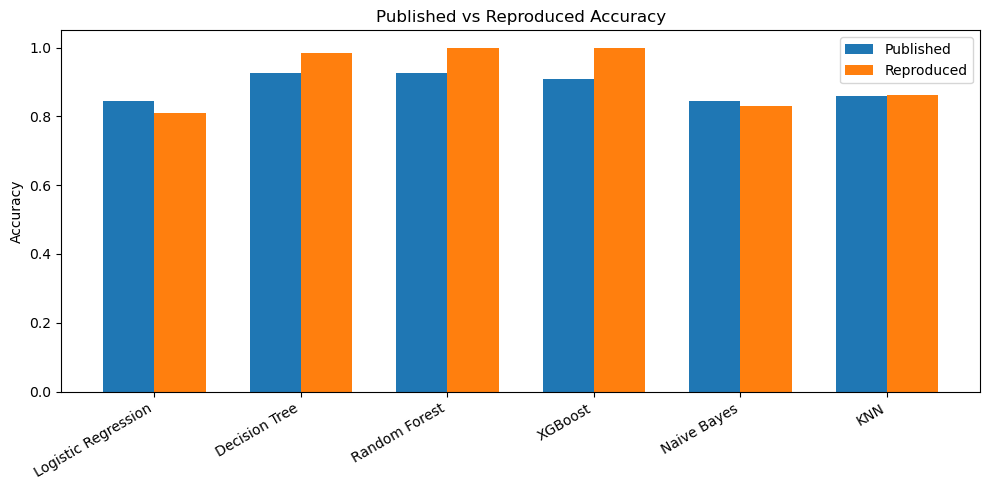

In [20]:
x = np.arange(len(comparison_df))
width = 0.35

plt.figure(figsize=(10, 5))

plt.bar(
    x - width/2,
    comparison_df["Published Accuracy"],
    width,
    label="Published"
)

plt.bar(
    x + width/2,
    comparison_df["Accuracy"],
    width,
    label="Reproduced"
)

plt.xticks(
    x,
    comparison_df["Model"],
    rotation=30,
    ha="right"
)

plt.ylabel("Accuracy")
plt.ylim(0, 1.05)
plt.title("Published vs Reproduced Accuracy")
plt.legend()

plt.tight_layout()
plt.show()

The comparison graph makes the differences between the published and reproduced results easier to see.

KNN and Naive Bayes produced results that are close to the values reported in the paper. Logistic Regression was slightly lower.

The biggest differences were found in Decision Tree, Random Forest and XGBoost, where my reproduced results were much higher.

One possible reason is the large number of duplicate rows in the dataset. Since the data was randomly split, identical records may appear in both the training and testing sets. This could make some models, especially tree-based models, perform better than expected.

Another possible reason is that the paper does not clearly provide every model parameter and random split setting, so small implementation differences may also affect the results.

# 4. Stacking Ensemble Model

The main contribution of the selected paper is the use of a stacking ensemble method.

The paper combines the six individual classifiers using a **5-fold stacking approach** so that predictions from the base models can be combined by a meta-classifier.

For my reproduction, I followed the 5-fold stacking structure described in the paper. Since the final meta-classifier setting is not clearly specified, I used Logistic Regression as a reasonable implementation choice.

In [21]:
stack_estimators = [
    (
        "lr",
        Pipeline([
            ("scaler", StandardScaler()),
            ("model", LogisticRegression(max_iter=1000, random_state=42))
        ])
    ),

    (
        "dt",
        DecisionTreeClassifier(random_state=42)
    ),

    (
        "rf",
        RandomForestClassifier(
            n_estimators=100,
            random_state=42
        )
    ),

    (
        "xgb",
        XGBClassifier(
            random_state=42,
            eval_metric="logloss"
        )
    ),

    (
        "nb",
        Pipeline([
            ("scaler", StandardScaler()),
            ("model", GaussianNB())
        ])
    ),

    (
        "knn",
        Pipeline([
            ("scaler", StandardScaler()),
            ("model", KNeighborsClassifier(n_neighbors=5))
        ])
    )
]

stacking_model = StackingClassifier(
    estimators=stack_estimators,
    final_estimator=LogisticRegression(max_iter=1000, random_state=42),
    cv=5,
    stack_method="predict_proba"
)

stacking_model.fit(X_train, y_train)

stack_pred = stacking_model.predict(X_test)
stack_prob = stacking_model.predict_proba(X_test)[:, 1]

stack_accuracy = accuracy_score(y_test, stack_pred)
stack_precision = precision_score(y_test, stack_pred)
stack_recall = recall_score(y_test, stack_pred)
stack_f1 = f1_score(y_test, stack_pred)
stack_auc = roc_auc_score(y_test, stack_prob)

print("Stacking Ensemble")
print("Accuracy :", round(stack_accuracy, 4))
print("Precision:", round(stack_precision, 4))
print("Recall   :", round(stack_recall, 4))
print("F1-score :", round(stack_f1, 4))
print("AUC      :", round(stack_auc, 4))

Stacking Ensemble
Accuracy : 1.0
Precision: 1.0
Recall   : 1.0
F1-score : 1.0
AUC      : 1.0


The stacking ensemble achieved **100%** for Accuracy, Precision, Recall, F1-score and AUC.

This is slightly higher than the **98.53% accuracy** reported in the selected paper.

Although this looks like a very strong result, I should not assume that the model will always perform perfectly on new patients. The dataset contains many duplicate records, and some identical records may be present in both the training and testing sets.

Because of this, the perfect result may partly come from data leakage caused by duplicate records rather than only from the strength of the stacking model.

This will be investigated further in the improvement section.

## 4.1 Stacking Model Evaluation

To examine the stacking model in more detail, I also checked its confusion matrix and ROC curve.

The confusion matrix shows how many positive and negative cases were classified correctly, while the ROC curve shows how well the model separates the two target classes.

In [22]:
cm = confusion_matrix(y_test, stack_pred)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[100   0]
 [  0 105]]


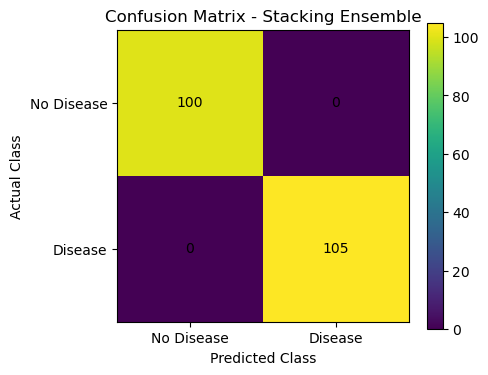

In [23]:
plt.figure(figsize=(5, 4))

plt.imshow(cm)

plt.title("Confusion Matrix - Stacking Ensemble")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.xticks([0, 1], ["No Disease", "Disease"])
plt.yticks([0, 1], ["No Disease", "Disease"])

for i in range(2):
    for j in range(2):
        plt.text(j, i, cm[i, j], ha="center", va="center")

plt.colorbar()
plt.tight_layout()
plt.show()

The confusion matrix shows that the stacking model classified all **205 test records correctly**.

It correctly predicted **100 no-heart-disease cases** and **105 heart-disease cases**, with no false positives or false negatives.

This explains why the model achieved 100% Accuracy, Precision, Recall and F1-score on this test split.

However, this perfect result should still be interpreted carefully because the dataset contains many duplicate records. A model may perform extremely well if identical patient records are present in both the training and testing sets.

## 4.2 ROC Curve of the Stacking Model

I also plotted the ROC curve to check how well the stacking model separates the two target classes.

A model with an AUC value closer to 1.0 has better ability to distinguish between heart disease and no heart disease.

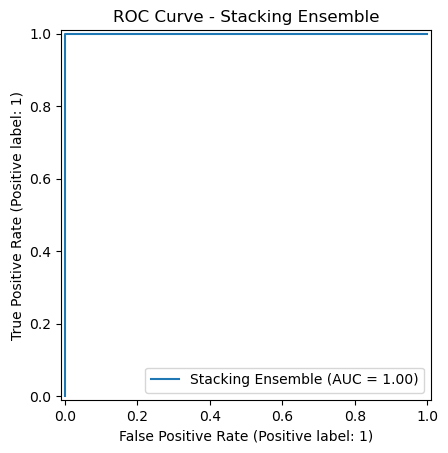

In [24]:
RocCurveDisplay.from_predictions(
    y_test,
    stack_prob,
    name="Stacking Ensemble"
)

plt.title("ROC Curve - Stacking Ensemble")
plt.show()

The ROC curve gives an AUC value of **1.00**, which means the stacking model perfectly separated the two classes in this test set.

This matches the other evaluation results, where the stacking model achieved 100% accuracy.

However, a perfect result is unusual for a medical prediction problem, so I will examine the dataset and evaluation setup more carefully before deciding how reliable this result is.

## 4.3 Final Results of the Reproduction Study

To summarise Part 1, I combined the results from all six individual classifiers and the stacking ensemble into one table.

This makes it easier to compare the reproduced models and see how the stacking model performed against the individual classifiers.

In [25]:
stack_result = pd.DataFrame([{
    "Model": "Stacking Ensemble",
    "Accuracy": stack_accuracy,
    "Precision": stack_precision,
    "Recall": stack_recall,
    "F1-score": stack_f1,
    "AUC": stack_auc
}])

final_results_df = pd.concat(
    [results_df, stack_result],
    ignore_index=True
)

display(final_results_df.round(4))

,Model,Accuracy,Precision,Recall,F1-score,AUC
0,Logistic Regression,0.8098,0.7619,0.9143,0.8312,0.9298
1,Decision Tree,0.9854,1.0000,0.9714,0.9855,0.9857
2,Random Forest,1.0000,1.0000,1.0000,1.0000,1.0000
3,XGBoost,1.0000,1.0000,1.0000,1.0000,1.0000
4,Naive Bayes,0.8293,0.8070,0.8762,0.8402,0.9043
5,KNN,0.8634,0.8738,0.8571,0.8654,0.9629
6,Stacking Ensemble,1.0000,1.0000,1.0000,1.0000,1.0000


The final reproduction results show that the stacking ensemble achieved the highest performance in my experiment.

Random Forest and XGBoost also achieved perfect results, while Decision Tree performed very strongly. Logistic Regression and Naive Bayes produced lower results, and KNN was close to the published value.

Because some of the reproduced results are much higher than those reported in the paper, I will now compare the final reproduced accuracies directly with the published accuracies and investigate possible reasons for the differences.

## 4.4 Published vs Reproduced Final Comparison

The table below compares the published accuracy of each model with the accuracy obtained in my reproduction.

This comparison helps identify which models were reproduced closely and which models showed larger differences.

In [26]:
published_all = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest",
        "XGBoost",
        "Naive Bayes",
        "KNN",
        "Stacking Ensemble"
    ],
    "Published Accuracy": [
        0.8439,
        0.9268,
        0.9268,
        0.9073,
        0.8439,
        0.8585,
        0.9853
    ]
})

final_comparison = pd.merge(
    published_all,
    final_results_df[["Model", "Accuracy"]],
    on="Model"
)

final_comparison["Difference"] = (
    final_comparison["Accuracy"] -
    final_comparison["Published Accuracy"]
)

display(final_comparison.round(4))

,Model,Published Accuracy,Accuracy,Difference
0,Logistic Regression,0.8439,0.8098,-0.0341
1,Decision Tree,0.9268,0.9854,0.0586
2,Random Forest,0.9268,1.0000,0.0732
3,XGBoost,0.9073,1.0000,0.0927
4,Naive Bayes,0.8439,0.8293,-0.0146
5,KNN,0.8585,0.8634,0.0049
6,Stacking Ensemble,0.9853,1.0000,0.0147


The final comparison shows that some reproduced results are close to the published results, while others are noticeably higher.

KNN produced the closest result to the paper, with only a very small difference. Naive Bayes and Logistic Regression were also reasonably close.

The largest differences were found in Decision Tree, Random Forest and XGBoost. These models achieved much higher accuracy in my reproduction than in the published study.

The stacking ensemble achieved **100% accuracy**, which is slightly higher than the **98.53%** reported in the paper.

Because several models performed unusually well, I investigated whether the train-test split contained duplicate records that could have affected the evaluation.

## 4.5 Checking for Duplicate Leakage

To check this, I compared the test records with the training records to see whether identical patient records appeared in both sets.

If the same record is present in both training and testing data, the model may be evaluated on information it has already seen. This can make the reported performance look higher than the model's true performance on new patients.

In [27]:
train_rows = X_train.copy()
train_rows["target"] = y_train.values

test_rows = X_test.copy()
test_rows["target"] = y_test.values

overlap = test_rows.merge(
    train_rows.drop_duplicates(),
    how="inner"
)

print("Test records:", len(test_rows))
print("Test records also found in training:", len(overlap))

print(
    "Percentage of test records also found in training:",
    round((len(overlap) / len(test_rows)) * 100, 2),
    "%"
)

Test records: 205
Test records also found in training: 202
Percentage of test records also found in training: 98.54 %


The duplicate check shows that **202 out of 205 test records** were also present in the training set.

This means that **98.54% of the test set was already represented in the training data**.

This is a major limitation because the models were not being tested mainly on completely unseen patient records. This likely explains why Random Forest, XGBoost and the stacking ensemble achieved extremely high or perfect results.

Because of this finding, I will redesign the evaluation process in Part 2 so that duplicate records are removed before creating the training and testing sets.

# Part 2 – Improved Machine Learning Solution

## 5.1 Limitation Identified

The main limitation I identified in the reproduced approach is duplicate data leakage between the training and testing sets.

Since most test records were also present in the training data, the original random split can give an overly optimistic estimate of model performance.

For the improved method, I will first remove duplicate records before splitting the dataset. I will then retrain and evaluate the models using a cleaner setup so that the test set contains unseen records.

## 5.2 Creating a Duplicate-Free Dataset

To improve the evaluation, I first removed duplicate rows from the dataset before creating the new training and testing sets.

This makes sure that the same patient record cannot appear in both sets.

After removing duplicates, I checked the new dataset size and target distribution before continuing with model training.

In [28]:
clean_df = df.drop_duplicates().reset_index(drop=True)

print("Original dataset shape:", df.shape)
print("Duplicate-free dataset shape:", clean_df.shape)

print("\nTarget distribution:")
print(clean_df["target"].value_counts())

print("\nTarget percentages:")
print((clean_df["target"].value_counts(normalize=True) * 100).round(2))

Original dataset shape: (1025, 14)
Duplicate-free dataset shape: (302, 14)

Target distribution:
target
1    164
0    138
Name: count, dtype: int64

Target percentages:
target
1    54.3
0    45.7
Name: proportion, dtype: float64


After removing duplicate records, the dataset was reduced from **1,025 rows to 302 unique rows**.

The target classes are still reasonably balanced, with around **54.3% heart disease cases** and **45.7% no-heart-disease cases**.

This cleaned dataset will be used for the improved evaluation so that the same patient record cannot appear in both the training and testing sets.

## 5.3 Creating the Clean Train-Test Split

Next, I separated the cleaned dataset into input features and target values.

I again used an **80% training and 20% testing split** with stratification so that both target classes remain represented in similar proportions.

Because duplicate records were removed before the split, the new test set should contain unseen records.

In [29]:
X_clean = clean_df.drop("target", axis=1)
y_clean = clean_df["target"]

X_train_clean, X_test_clean, y_train_clean, y_test_clean = train_test_split(
    X_clean,
    y_clean,
    test_size=0.20,
    random_state=42,
    stratify=y_clean
)

print("Clean training features:", X_train_clean.shape)
print("Clean testing features:", X_test_clean.shape)

print("\nTraining target distribution:")
print(y_train_clean.value_counts(normalize=True).round(3))

print("\nTesting target distribution:")
print(y_test_clean.value_counts(normalize=True).round(3))

Clean training features: (241, 13)
Clean testing features: (61, 13)

Training target distribution:
target
1    0.544
0    0.456
Name: proportion, dtype: float64

Testing target distribution:
target
1    0.541
0    0.459
Name: proportion, dtype: float64


The cleaned dataset was split into **241 training records and 61 testing records**.

The target distribution remained similar in both sets, so the stratified split worked correctly.

Before retraining the models, I checked whether any identical records were still shared between the new training and testing sets.

## 5.4 Verifying Zero Overlap

Since duplicate records were removed before splitting, the new training and testing sets should not contain identical patient records.

I checked this directly to make sure the improved evaluation setup does not contain the same leakage problem found in Part 1.

In [30]:
train_clean_rows = X_train_clean.copy()
train_clean_rows["target"] = y_train_clean.values

test_clean_rows = X_test_clean.copy()
test_clean_rows["target"] = y_test_clean.values

clean_overlap = test_clean_rows.merge(
    train_clean_rows,
    how="inner"
)

print("Clean test records:", len(test_clean_rows))
print("Test records also found in clean training set:", len(clean_overlap))

Clean test records: 61
Test records also found in clean training set: 0


The overlap check confirms that there are **0 identical records** shared between the cleaned training and testing sets.

This means the improved evaluation is now testing the models on unseen records instead of records that were already present in the training data.

This should give a more realistic estimate of how well the models can generalise to new patients.

## 5.5 Preparing the Clean Data for Model Training

Before retraining the models, I prepared scaled versions of the cleaned training and testing data.

Scaling is needed for models such as Logistic Regression and KNN, while the tree-based models can continue using the original feature values.

In [31]:
clean_scaler = StandardScaler()

X_train_clean_scaled = clean_scaler.fit_transform(X_train_clean)
X_test_clean_scaled = clean_scaler.transform(X_test_clean)

print("Scaled clean training shape:", X_train_clean_scaled.shape)
print("Scaled clean testing shape:", X_test_clean_scaled.shape)

Scaled clean training shape: (241, 13)
Scaled clean testing shape: (61, 13)


The cleaned training and testing data were scaled successfully.

The training set contains **241 records with 13 features**, while the test set contains **61 records with 13 features**.

## 5.6 Retraining the Individual Models

I now retrained the same six machine learning classifiers using the duplicate-free dataset.

I kept the model types consistent with Part 1 so that the main difference is the improved evaluation setup rather than changing the classifiers.

A separate evaluation function is used here because the cleaned experiment has its own training and testing target values.

In [32]:
clean_results = []

def evaluate_clean_model(name, model, X_train_data, X_test_data):
    model.fit(X_train_data, y_train_clean)

    y_pred = model.predict(X_test_data)
    y_prob = model.predict_proba(X_test_data)[:, 1]

    accuracy = accuracy_score(y_test_clean, y_pred)
    precision = precision_score(y_test_clean, y_pred)
    recall = recall_score(y_test_clean, y_pred)
    f1 = f1_score(y_test_clean, y_pred)
    auc = roc_auc_score(y_test_clean, y_prob)

    clean_results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-score": f1,
        "AUC": auc
    })

    print(name)
    print("Accuracy :", round(accuracy, 4))
    print("Precision:", round(precision, 4))
    print("Recall   :", round(recall, 4))
    print("F1-score :", round(f1, 4))
    print("AUC      :", round(auc, 4))
    print()

    return model, y_pred, y_prob

### Logistic Regression on the Clean Dataset

I first retrained Logistic Regression using the duplicate-free dataset.

I used the scaled training and testing data because Logistic Regression can be affected by differences in feature scale.

This result will be compared with the Logistic Regression result from Part 1 to see how removing duplicate leakage affects performance.

In [33]:
clean_lr = LogisticRegression(
    max_iter=1000,
    random_state=42
)

clean_lr, clean_lr_pred, clean_lr_prob = evaluate_clean_model(
    "Logistic Regression",
    clean_lr,
    X_train_clean_scaled,
    X_test_clean_scaled
)

Logistic Regression
Accuracy : 0.8033
Precision: 0.8
Recall   : 0.8485
F1-score : 0.8235
AUC      : 0.8712



The clean Logistic Regression model achieved an accuracy of **80.33%**.

Its precision was **80.00%**, recall was **84.85%**, F1-score was **82.35%**, and AUC was **87.12%**.

The accuracy is close to the Logistic Regression result from Part 1, but the AUC is lower. This suggests that removing duplicate leakage had a stronger effect on how well the model separates the two classes.

### Decision Tree on the Clean Dataset

Next, I retrained the Decision Tree using the duplicate-free dataset.

Decision Trees do not require feature scaling, so I used the original cleaned training and testing features.

This result is important because the Decision Tree achieved a very high score in Part 1, and I want to check how much of that performance was affected by duplicate leakage.

In [34]:
clean_dt = DecisionTreeClassifier(
    random_state=42
)

clean_dt, clean_dt_pred, clean_dt_prob = evaluate_clean_model(
    "Decision Tree",
    clean_dt,
    X_train_clean,
    X_test_clean
)

Decision Tree
Accuracy : 0.8033
Precision: 0.8182
Recall   : 0.8182
F1-score : 0.8182
AUC      : 0.8019



The clean Decision Tree achieved an accuracy of **80.33%**.

Its precision was **81.82%**, recall was **81.82%**, F1-score was **81.82%**, and AUC was **80.19%**.

This is much lower than the Decision Tree result from Part 1. The large drop after removing duplicate records suggests that the previous high result was strongly affected by duplicate leakage.

### Random Forest on the Clean Dataset

Next, I retrained Random Forest using the duplicate-free dataset.

Random Forest achieved a perfect result in Part 1, so this test is important for checking how much that performance changes when the model is evaluated on unseen records.

Since Random Forest is tree-based, I used the original cleaned feature values without scaling.

In [35]:
clean_rf = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

clean_rf, clean_rf_pred, clean_rf_prob = evaluate_clean_model(
    "Random Forest",
    clean_rf,
    X_train_clean,
    X_test_clean
)

Random Forest
Accuracy : 0.7541
Precision: 0.7647
Recall   : 0.7879
F1-score : 0.7761
AUC      : 0.8615



The clean Random Forest model achieved an accuracy of **75.41%**.

Its precision was **76.47%**, recall was **78.79%**, F1-score was **77.61%**, and AUC was **86.15%**.

This is much lower than the perfect Random Forest result from Part 1. The large drop after removing duplicate records shows that the previous result did not represent true performance on unseen patient records.

### XGBoost on the Clean Dataset

Next, I retrained XGBoost using the duplicate-free dataset.

XGBoost also achieved a perfect result in Part 1, so this experiment helps check how much of that performance was caused by duplicate leakage.

Since XGBoost is tree-based, I used the original cleaned training and testing features without scaling.

In [36]:
clean_xgb = XGBClassifier(
    random_state=42,
    eval_metric="logloss"
)

clean_xgb, clean_xgb_pred, clean_xgb_prob = evaluate_clean_model(
    "XGBoost",
    clean_xgb,
    X_train_clean,
    X_test_clean
)

XGBoost
Accuracy : 0.7213
Precision: 0.7353
Recall   : 0.7576
F1-score : 0.7463
AUC      : 0.8323



The clean XGBoost model achieved an accuracy of **72.13%**.

Its precision was **73.53%**, recall was **75.76%**, F1-score was **74.63%**, and AUC was **83.23%**.

This is much lower than the perfect XGBoost result from Part 1. The drop in performance after removing duplicate records shows that the earlier result was strongly affected by the duplicated data.

### Naive Bayes on the Clean Dataset

Next, I retrained Naive Bayes using the duplicate-free dataset.

Naive Bayes did not show an extreme result in Part 1, so this helps check whether its performance is more stable when duplicate leakage is removed.

I used the scaled clean training and testing data for this model.

In [37]:
clean_nb = GaussianNB()

clean_nb, clean_nb_pred, clean_nb_prob = evaluate_clean_model(
    "Naive Bayes",
    clean_nb,
    X_train_clean_scaled,
    X_test_clean_scaled
)

Naive Bayes
Accuracy : 0.7869
Precision: 0.8333
Recall   : 0.7576
F1-score : 0.7937
AUC      : 0.8842



The clean Naive Bayes model achieved an accuracy of **78.69%**.

Its precision was **83.33%**, recall was **75.76%**, F1-score was **79.37%**, and AUC was **88.42%**.

The result is lower than the Naive Bayes result from Part 1, but the change is smaller than what was seen for Random Forest and XGBoost.

### K-Nearest Neighbours on the Clean Dataset

The final individual model I retrained is K-Nearest Neighbours.

KNN uses the distance between data points to make predictions, so I used the scaled clean training and testing data.

This will show how KNN performs when it is tested only on unseen records.

In [38]:
clean_knn = KNeighborsClassifier(n_neighbors=5)

clean_knn, clean_knn_pred, clean_knn_prob = evaluate_clean_model(
    "KNN",
    clean_knn,
    X_train_clean_scaled,
    X_test_clean_scaled
)

KNN
Accuracy : 0.7869
Precision: 0.7778
Recall   : 0.8485
F1-score : 0.8116
AUC      : 0.8377



The clean KNN model achieved an accuracy of **78.69%**.

Its precision was **77.78%**, recall was **84.85%**, F1-score was **81.16%**, and AUC was **83.77%**.

The result is lower than the KNN result from Part 1, but the change is smaller than the drops seen in Random Forest and XGBoost.

## 5.7 Comparison of the Clean Individual Models

After retraining all six classifiers on the duplicate-free dataset, I combined their results into one table.

This allows me to compare the performance of the individual models under the improved evaluation setup.

In [39]:
clean_results_df = pd.DataFrame(clean_results)

clean_results_df = clean_results_df[
    ["Model", "Accuracy", "Precision", "Recall", "F1-score", "AUC"]
]

display(clean_results_df.round(4))

,Model,Accuracy,Precision,Recall,F1-score,AUC
0,Logistic Regression,0.8033,0.8000,0.8485,0.8235,0.8712
1,Decision Tree,0.8033,0.8182,0.8182,0.8182,0.8019
2,Random Forest,0.7541,0.7647,0.7879,0.7761,0.8615
3,XGBoost,0.7213,0.7353,0.7576,0.7463,0.8323
4,Naive Bayes,0.7869,0.8333,0.7576,0.7937,0.8842
5,KNN,0.7869,0.7778,0.8485,0.8116,0.8377


## 5.8 Stacking Ensemble on the Clean Dataset

After evaluating the six individual models on the duplicate-free dataset, I rebuilt the stacking ensemble using the same six base classifiers.

The aim is to check how the stacking method performs when the test data contains unseen records and no duplicate leakage.

I kept the same general stacking structure used in Part 1, including 5-fold cross-validation and Logistic Regression as the final meta-classifier.

In [40]:
clean_stack_estimators = [
    (
        "lr",
        Pipeline([
            ("scaler", StandardScaler()),
            ("model", LogisticRegression(max_iter=1000, random_state=42))
        ])
    ),

    (
        "dt",
        DecisionTreeClassifier(random_state=42)
    ),

    (
        "rf",
        RandomForestClassifier(
            n_estimators=100,
            random_state=42
        )
    ),

    (
        "xgb",
        XGBClassifier(
            random_state=42,
            eval_metric="logloss"
        )
    ),

    (
        "nb",
        Pipeline([
            ("scaler", StandardScaler()),
            ("model", GaussianNB())
        ])
    ),

    (
        "knn",
        Pipeline([
            ("scaler", StandardScaler()),
            ("model", KNeighborsClassifier(n_neighbors=5))
        ])
    )
]

clean_stacking_model = StackingClassifier(
    estimators=clean_stack_estimators,
    final_estimator=LogisticRegression(max_iter=1000, random_state=42),
    cv=5,
    stack_method="predict_proba"
)

clean_stacking_model.fit(X_train_clean, y_train_clean)

clean_stack_pred = clean_stacking_model.predict(X_test_clean)
clean_stack_prob = clean_stacking_model.predict_proba(X_test_clean)[:, 1]

clean_stack_accuracy = accuracy_score(y_test_clean, clean_stack_pred)
clean_stack_precision = precision_score(y_test_clean, clean_stack_pred)
clean_stack_recall = recall_score(y_test_clean, clean_stack_pred)
clean_stack_f1 = f1_score(y_test_clean, clean_stack_pred)
clean_stack_auc = roc_auc_score(y_test_clean, clean_stack_prob)

print("Clean Stacking Ensemble")
print("Accuracy :", round(clean_stack_accuracy, 4))
print("Precision:", round(clean_stack_precision, 4))
print("Recall   :", round(clean_stack_recall, 4))
print("F1-score :", round(clean_stack_f1, 4))
print("AUC      :", round(clean_stack_auc, 4))

Clean Stacking Ensemble
Accuracy : 0.7541
Precision: 0.7647
Recall   : 0.7879
F1-score : 0.7761
AUC      : 0.8669


The clean stacking ensemble achieved an accuracy of **75.41%**.

Its precision was **76.47%**, recall was **78.79%**, F1-score was **77.61%**, and AUC was **86.69%**.

This is much lower than the 100% stacking result from Part 1.

The large drop shows that the perfect result from the original reproduction was strongly affected by duplicate leakage. When the same patient records are removed before splitting, the stacking model gives a more realistic estimate of performance on unseen data.

## 5.9 Comparing Original and Improved Evaluation

To see the effect of the improved evaluation clearly, I compared the Part 1 results with the results obtained after removing duplicate records.

This comparison helps show how much the duplicate leakage affected each model.

In [41]:
clean_stack_result = pd.DataFrame([{
    "Model": "Stacking Ensemble",
    "Accuracy": clean_stack_accuracy,
    "Precision": clean_stack_precision,
    "Recall": clean_stack_recall,
    "F1-score": clean_stack_f1,
    "AUC": clean_stack_auc
}])

clean_final_results = pd.concat(
    [clean_results_df, clean_stack_result],
    ignore_index=True
)

comparison_improved = pd.merge(
    final_results_df[["Model", "Accuracy"]].rename(
        columns={"Accuracy": "Part 1 Accuracy"}
    ),
    clean_final_results[["Model", "Accuracy"]].rename(
        columns={"Accuracy": "Clean Accuracy"}
    ),
    on="Model"
)

comparison_improved["Change"] = (
    comparison_improved["Clean Accuracy"] -
    comparison_improved["Part 1 Accuracy"]
)

display(comparison_improved.round(4))

,Model,Part 1 Accuracy,Clean Accuracy,Change
0,Logistic Regression,0.8098,0.8033,-0.0065
1,Decision Tree,0.9854,0.8033,-0.1821
2,Random Forest,1.0000,0.7541,-0.2459
3,XGBoost,1.0000,0.7213,-0.2787
4,Naive Bayes,0.8293,0.7869,-0.0424
5,KNN,0.8634,0.7869,-0.0765
6,Stacking Ensemble,1.0000,0.7541,-0.2459


The comparison shows that removing duplicate leakage changed the results significantly.

Logistic Regression changed only slightly, but the tree-based models showed much larger drops in accuracy.

Decision Tree dropped by about **18 percentage points**, Random Forest by about **25 percentage points**, and XGBoost by about **28 percentage points**.

The stacking ensemble also dropped from **100% accuracy to 75.41%**.

These results show that the very high scores from Part 1 were not a reliable estimate of performance on unseen patients. The improved evaluation gives a more realistic result because the training and testing sets no longer contain identical records.

## 5.10 Visual Comparison of Part 1 and Clean Evaluation

To make the effect of duplicate leakage easier to see, I plotted the Part 1 accuracy and clean accuracy for each model.

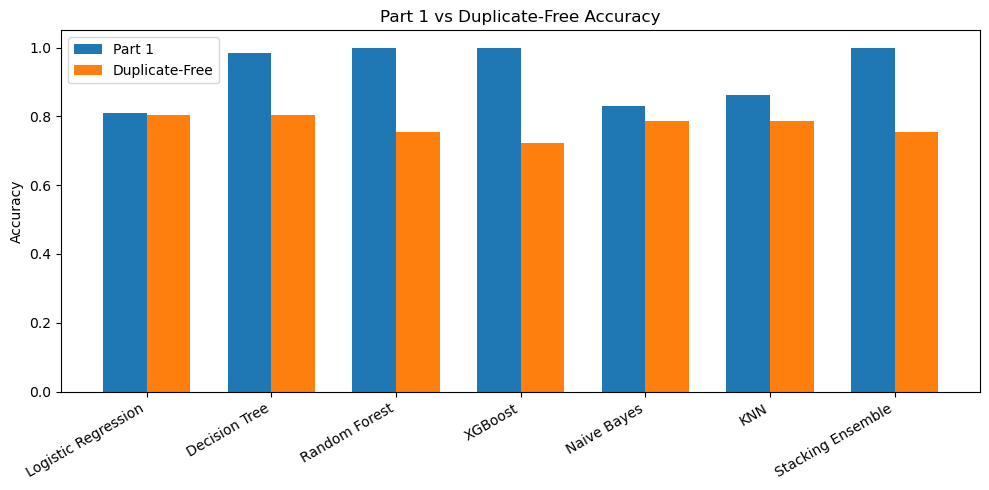

In [42]:
x = np.arange(len(comparison_improved))
width = 0.35

plt.figure(figsize=(10, 5))

plt.bar(
    x - width/2,
    comparison_improved["Part 1 Accuracy"],
    width,
    label="Part 1"
)

plt.bar(
    x + width/2,
    comparison_improved["Clean Accuracy"],
    width,
    label="Duplicate-Free"
)

plt.xticks(
    x,
    comparison_improved["Model"],
    rotation=30,
    ha="right"
)

plt.ylabel("Accuracy")
plt.ylim(0, 1.05)
plt.title("Part 1 vs Duplicate-Free Accuracy")
plt.legend()

plt.tight_layout()
plt.show()

The graph clearly shows the effect of duplicate leakage on model performance.

Logistic Regression changed only slightly, while Decision Tree, Random Forest, XGBoost and the stacking ensemble showed much larger drops after duplicate records were removed.

This supports the finding that the extremely high results in Part 1 were not fully reliable because most of the original test set was already represented in the training data.

The duplicate-free evaluation gives a more realistic picture of how the models perform on unseen patient records.

## 5.11 Final Comparison

To summarise the experiment, I compared three sets of results:

- the accuracy reported in the published paper
- my Part 1 reproduction using the original 1,025-row dataset
- the duplicate-free evaluation from Part 2

This final comparison shows how the reported performance changes when duplicate leakage is removed.

In [43]:
final_three_way = pd.merge(
    published_all,
    final_results_df[["Model", "Accuracy"]].rename(
        columns={"Accuracy": "Part 1 Accuracy"}
    ),
    on="Model"
)

final_three_way = pd.merge(
    final_three_way,
    clean_final_results[["Model", "Accuracy"]].rename(
        columns={"Accuracy": "Duplicate-Free Accuracy"}
    ),
    on="Model"
)

display(final_three_way.round(4))

,Model,Published Accuracy,Part 1 Accuracy,Duplicate-Free Accuracy
0,Logistic Regression,0.8439,0.8098,0.8033
1,Decision Tree,0.9268,0.9854,0.8033
2,Random Forest,0.9268,1.0000,0.7541
3,XGBoost,0.9073,1.0000,0.7213
4,Naive Bayes,0.8439,0.8293,0.7869
5,KNN,0.8585,0.8634,0.7869
6,Stacking Ensemble,0.9853,1.0000,0.7541


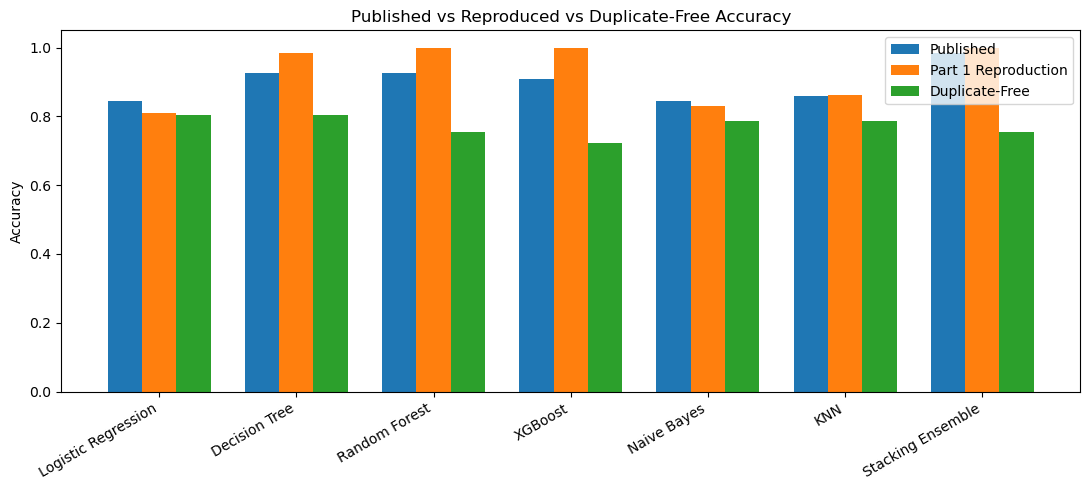

In [44]:
x = np.arange(len(final_three_way))
width = 0.25

plt.figure(figsize=(11, 5))

plt.bar(
    x - width,
    final_three_way["Published Accuracy"],
    width,
    label="Published"
)

plt.bar(
    x,
    final_three_way["Part 1 Accuracy"],
    width,
    label="Part 1 Reproduction"
)

plt.bar(
    x + width,
    final_three_way["Duplicate-Free Accuracy"],
    width,
    label="Duplicate-Free"
)

plt.xticks(
    x,
    final_three_way["Model"],
    rotation=30,
    ha="right"
)

plt.ylabel("Accuracy")
plt.ylim(0, 1.05)
plt.title("Published vs Reproduced vs Duplicate-Free Accuracy")
plt.legend()

plt.tight_layout()
plt.show()

The final comparison shows a clear difference between the published results, my original reproduction and the duplicate-free evaluation.

The Part 1 reproduction produced very high results for Decision Tree, Random Forest, XGBoost and the stacking ensemble. However, these results were affected by duplicate leakage because most test records were already present in the training data.

After removing duplicate records before splitting the dataset, the accuracy of these models dropped noticeably. The duplicate-free results are therefore a more realistic estimate of performance on unseen patient records.

Logistic Regression changed only slightly, while the largest performance drops were seen in XGBoost, Random Forest and the stacking ensemble.

Overall, this experiment shows that evaluation design can strongly affect machine learning results, especially when duplicate records are present in the dataset.


## 5.12 Repeated Cross-Validation on the Duplicate-Free Dataset

The duplicate-free dataset contains only **302 unique records**, so the result from one 80/20 train-test split may depend on how the data was divided.

To make the improved evaluation more reliable, I used **Repeated Stratified K-Fold Cross-Validation** on the duplicate-free dataset.

Stratification keeps the proportion of heart disease and no-heart-disease cases similar in each fold, while repeating the cross-validation allows the models to be tested across several different data splits.

For this experiment, I used **5 folds repeated 5 times**. I compared the mean Accuracy, Precision, Recall, F1-score and AUC for the six individual classifiers and the stacking ensemble.

This provides a more stable evaluation than relying only on one cleaned train-test split.

In [45]:
from sklearn.model_selection import RepeatedStratifiedKFold, cross_validate

In [46]:
cv = RepeatedStratifiedKFold(
    n_splits=5,
    n_repeats=5,
    random_state=42
)

scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "auc": "roc_auc"
}

### Cross-Validation Models

I used the same six individual classifiers and the same stacking structure from the previous experiment.

To avoid data leakage during cross-validation, scaling is included inside the pipelines for models that require it. This means the scaler is fitted separately inside each training fold instead of using information from the validation fold.

In [47]:
cv_models = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=1000, random_state=42))
    ]),

    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42
    ),

    "XGBoost": XGBClassifier(
        random_state=42,
        eval_metric="logloss"
    ),

    "Naive Bayes": Pipeline([
        ("scaler", StandardScaler()),
        ("model", GaussianNB())
    ]),

    "KNN": Pipeline([
        ("scaler", StandardScaler()),
        ("model", KNeighborsClassifier(n_neighbors=5))
    ])
}

In [48]:
cv_stack_estimators = [
    (
        "lr",
        Pipeline([
            ("scaler", StandardScaler()),
            ("model", LogisticRegression(max_iter=1000, random_state=42))
        ])
    ),

    ("dt", DecisionTreeClassifier(random_state=42)),

    (
        "rf",
        RandomForestClassifier(
            n_estimators=100,
            random_state=42
        )
    ),

    (
        "xgb",
        XGBClassifier(
            random_state=42,
            eval_metric="logloss"
        )
    ),

    (
        "nb",
        Pipeline([
            ("scaler", StandardScaler()),
            ("model", GaussianNB())
        ])
    ),

    (
        "knn",
        Pipeline([
            ("scaler", StandardScaler()),
            ("model", KNeighborsClassifier(n_neighbors=5))
        ])
    )
]

cv_models["Stacking Ensemble"] = StackingClassifier(
    estimators=cv_stack_estimators,
    final_estimator=LogisticRegression(max_iter=1000, random_state=42),
    cv=5,
    stack_method="predict_proba"
)

In [49]:
cv_results = []

for name, model in cv_models.items():
    scores = cross_validate(
        model,
        X_clean,
        y_clean,
        cv=cv,
        scoring=scoring,
        n_jobs=-1
    )

    cv_results.append({
        "Model": name,
        "Accuracy Mean": scores["test_accuracy"].mean(),
        "Accuracy Std": scores["test_accuracy"].std(),

        "Precision Mean": scores["test_precision"].mean(),
        "Precision Std": scores["test_precision"].std(),

        "Recall Mean": scores["test_recall"].mean(),
        "Recall Std": scores["test_recall"].std(),

        "F1 Mean": scores["test_f1"].mean(),
        "F1 Std": scores["test_f1"].std(),

        "AUC Mean": scores["test_auc"].mean(),
        "AUC Std": scores["test_auc"].std()
    })

cv_results_df = pd.DataFrame(cv_results)

display(cv_results_df.round(4))

,Model,Accuracy Mean,Accuracy Std,Precision Mean,Precision Std,Recall Mean,Recall Std,F1 Mean,F1 Std,AUC Mean,AUC Std
0,Logistic Regression,0.8205,0.0271,0.8134,0.0447,0.8767,0.0677,0.8408,0.0260,0.9016,0.0251
1,Decision Tree,0.7622,0.0584,0.7750,0.0519,0.7940,0.0838,0.7825,0.0579,0.7593,0.0574
2,Random Forest,0.8265,0.0342,0.8271,0.0452,0.8657,0.0586,0.8439,0.0315,0.9019,0.0298
3,XGBoost,0.8019,0.0494,0.8114,0.0490,0.8316,0.0784,0.8189,0.0499,0.8781,0.0313
4,Naive Bayes,0.8151,0.0383,0.8224,0.0450,0.8464,0.0704,0.8317,0.0383,0.8962,0.0330
5,KNN,0.8146,0.0375,0.8096,0.0492,0.8671,0.0515,0.8356,0.0325,0.8814,0.0385
6,Stacking Ensemble,0.8298,0.0357,0.8253,0.0465,0.8769,0.0661,0.8478,0.0344,0.9036,0.0324


### Repeated Cross-Validation Results

The repeated cross-validation results give a more stable view of model performance on the duplicate-free dataset.

Across the 25 validation runs, the stacking ensemble achieved the highest mean accuracy of **82.90%**, with a standard deviation of about **3.57%**.

The stacking model also achieved a mean precision of **82.53%**, recall of **87.69%**, F1-score of **84.78%**, and AUC of **90.36%**.

Random Forest also performed strongly with a mean accuracy of **82.65%**, while Logistic Regression achieved **82.05%**.

These results are higher than some of the values from the single 80/20 clean split. This shows why relying on only one train-test split can give a result that depends too much on one particular division of a small dataset.

The repeated cross-validation results provide a more reliable estimate of performance while still preventing the duplicate leakage found in Part 1.

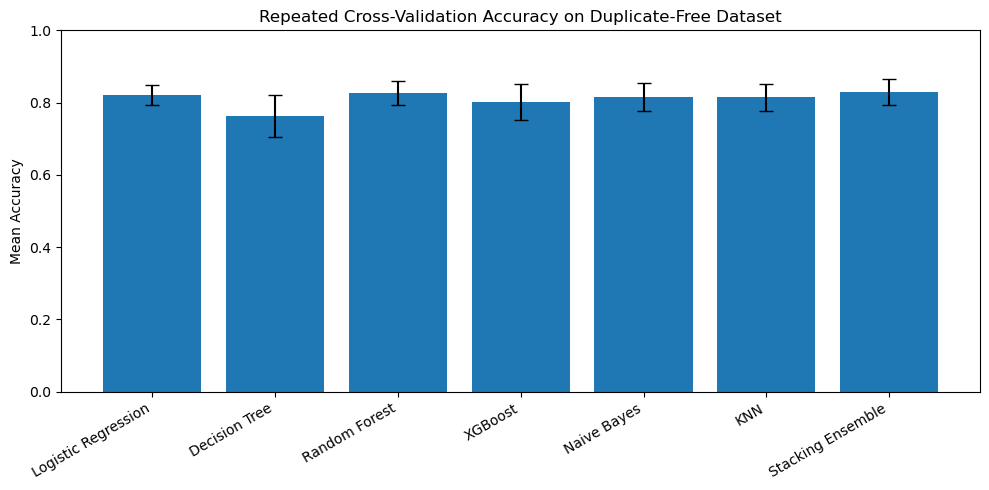

In [50]:
plt.figure(figsize=(10, 5))

plt.bar(
    cv_results_df["Model"],
    cv_results_df["Accuracy Mean"],
    yerr=cv_results_df["Accuracy Std"],
    capsize=5
)

plt.ylabel("Mean Accuracy")
plt.ylim(0, 1.0)
plt.title("Repeated Cross-Validation Accuracy on Duplicate-Free Dataset")

plt.xticks(rotation=30, ha="right")

plt.tight_layout()
plt.show()

## 5.13 Final Comparison Using Repeated Cross-Validation

The repeated cross-validation results provide the main evaluation of the improved method because they are based on 25 validation runs rather than one train-test split.

For the final comparison, I compare three sets of results:

- the accuracy reported in the selected paper
- the accuracy obtained in my Part 1 reproduction
- the mean accuracy obtained using repeated cross-validation on the duplicate-free dataset

This comparison shows how the results change when duplicate leakage is removed and the models are evaluated across several different data splits.

In [51]:
final_cv_comparison = pd.merge(
    published_all[["Model", "Published Accuracy"]],
    final_results_df[["Model", "Accuracy"]].rename(
        columns={"Accuracy": "Part 1 Accuracy"}
    ),
    on="Model"
)

final_cv_comparison = pd.merge(
    final_cv_comparison,
    cv_results_df[["Model", "Accuracy Mean", "Accuracy Std"]],
    on="Model"
)

final_cv_comparison = final_cv_comparison.rename(
    columns={
        "Accuracy Mean": "Repeated CV Accuracy",
        "Accuracy Std": "Repeated CV Std"
    }
)

display(final_cv_comparison.round(4))

,Model,Published Accuracy,Part 1 Accuracy,Repeated CV Accuracy,Repeated CV Std
0,Logistic Regression,0.8439,0.8098,0.8205,0.0271
1,Decision Tree,0.9268,0.9854,0.7622,0.0584
2,Random Forest,0.9268,1.0000,0.8265,0.0342
3,XGBoost,0.9073,1.0000,0.8019,0.0494
4,Naive Bayes,0.8439,0.8293,0.8151,0.0383
5,KNN,0.8585,0.8634,0.8146,0.0375
6,Stacking Ensemble,0.9853,1.0000,0.8298,0.0357


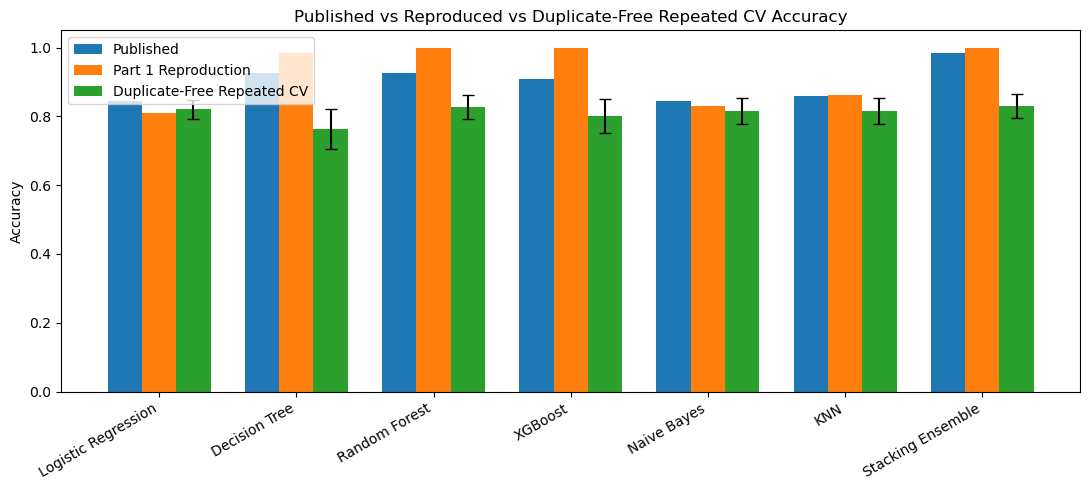

In [52]:
x = np.arange(len(final_cv_comparison))
width = 0.25

plt.figure(figsize=(11, 5))

plt.bar(
    x - width,
    final_cv_comparison["Published Accuracy"],
    width,
    label="Published"
)

plt.bar(
    x,
    final_cv_comparison["Part 1 Accuracy"],
    width,
    label="Part 1 Reproduction"
)

plt.bar(
    x + width,
    final_cv_comparison["Repeated CV Accuracy"],
    width,
    yerr=final_cv_comparison["Repeated CV Std"],
    capsize=4,
    label="Duplicate-Free Repeated CV"
)

plt.xticks(
    x,
    final_cv_comparison["Model"],
    rotation=30,
    ha="right"
)

plt.ylabel("Accuracy")
plt.ylim(0, 1.05)
plt.title("Published vs Reproduced vs Duplicate-Free Repeated CV Accuracy")
plt.legend()

plt.tight_layout()
plt.show()

The final comparison shows that the Part 1 reproduction produced much higher results for several models than the duplicate-free repeated evaluation.

The repeated cross-validation results are used as the main Part 2 results because they are based on 25 validation runs rather than one train-test split.

The stacking ensemble achieved a mean accuracy of **82.90% ± 3.57%** in the duplicate-free repeated evaluation, compared with **100%** in Part 1 and **98.53%** reported in the selected paper.

This provides a more realistic and stable estimate of model performance after the duplicate leakage was removed.

## 5.14 Feature Importance Check

The selected paper also discusses feature importance as part of the heart disease prediction process.

To compare this with my experiment, I used the Random Forest model trained on the duplicate-free dataset to examine the relative importance of the input features.

This does not remove any features from the model. It is only used to see which variables contributed more strongly to the Random Forest predictions.

In [53]:
feature_importance_df = pd.DataFrame({
    "Feature": X_train_clean.columns,
    "Importance": clean_rf.feature_importances_
}).sort_values(
    by="Importance",
    ascending=False
)

display(feature_importance_df)

,Feature,Importance
2,cp,0.173969
7,thalach,0.131634
11,ca,0.105700
9,oldpeak,0.096577
12,thal,0.090418
0,age,0.083049
8,exang,0.073679
3,trestbps,0.072088
4,chol,0.067384
1,sex,0.040229


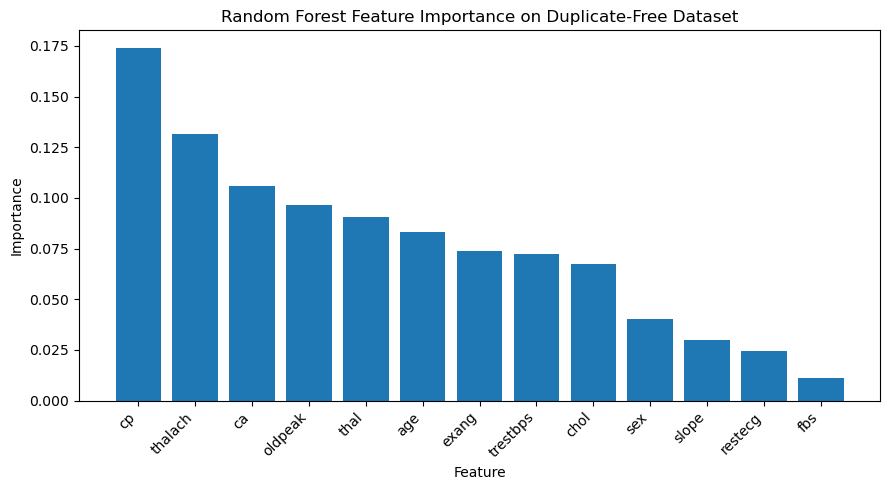

In [54]:
plt.figure(figsize=(9, 5))

plt.bar(
    feature_importance_df["Feature"],
    feature_importance_df["Importance"]
)

plt.xlabel("Feature")
plt.ylabel("Importance")
plt.title("Random Forest Feature Importance on Duplicate-Free Dataset")

plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()

The feature importance results show that `cp` had the highest importance in my Random Forest model, followed by `thalach` and `ca`.

The selected paper also identifies `thalach` as an important feature, although the overall ranking in my experiment is different.

This difference may be caused by the model settings, the removal of duplicate records and differences in the evaluation setup.

I kept all 13 input features for the final models because this feature importance check was used for comparison and analysis rather than feature removal.

# 6. Conclusion

In this notebook, I reproduced the heart disease prediction approach from the selected research paper using six individual machine learning classifiers and a stacking ensemble model.

The original reproduction produced results that were close to the paper for some models, but several tree-based models achieved extremely high or perfect accuracy.

Further checking showed that **202 out of 205 test records were also present in the training set**, which created duplicate data leakage.

To improve the evaluation, I removed duplicate records before creating the train-test split. This reduced the dataset from **1,025 records to 302 unique records** and removed overlap between the training and testing sets.

The single duplicate-free train-test split produced lower and more realistic results. The stacking ensemble achieved **75.41% accuracy** on that split.

Because the cleaned dataset is relatively small, I also used **Repeated Stratified 5-Fold Cross-Validation with 5 repeats**. Across the 25 validation runs, the stacking ensemble achieved a mean accuracy of **82.90%**, with a standard deviation of about **3.57%**.

The repeated cross-validation result gives a more stable estimate than relying on one single train-test split.

The main finding from this task is that very high accuracy does not always mean that a machine learning model will generalise well. Data quality, duplicate leakage and the evaluation method can strongly affect the reported performance.

## 6.1 Limitations and Future Work

There are still some limitations in this experiment.

First, after removing duplicate records, the dataset contains only **302 unique records**. This is still a relatively small dataset, so the results may not represent performance on a larger population.

Second, the selected paper does not clearly provide every implementation detail, such as the exact random split, all model hyperparameters and the final meta-classifier used in stacking. Because of this, some reasonable assumptions were required during the reproduction.

Although repeated cross-validation gives a more stable estimate, all experiments still use the same heart disease dataset. This means the models have not been tested on a completely independent external dataset.

In future work, the experiment could be improved by:

- testing the models on a larger independent heart disease dataset
- using nested cross-validation for model tuning
- comparing different meta-classifiers for the stacking ensemble
- testing feature selection methods
- checking model calibration
- evaluating the models on completely external patient data

These improvements could provide stronger evidence about how well the models generalise beyond this dataset.